# Baseline Model

In [1]:
#Possible future iterations
 #-Explore shipping_method_type
 #- Explore how to handle expiration date, in relation to order date+
 # - Explore county codes data treament, group by continent/else

#Review warning from the pd.to_datetime

#Imbalaces - any different approach to it or stay with stratrify in train_test_split, even worth having it there?

In [2]:
import os
import base64
import joblib
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.model_selection import cross_val_score
from category_encoders import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, roc_auc_score, confusion_matrix, pairwise, precision_recall_curve, roc_curve
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from sklearn.base import BaseEstimator, TransformerMixin

import category_encoders as ce
from sklearn.compose import ColumnTransformer, make_column_selector as selector
from sklearn.linear_model import LogisticRegression

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
%matplotlib inline

### Extract Data

In [3]:
#Import train data and have a quick glimpse to the content and shape
data = pd.read_csv("data/train.csv")
data.shape

(195401, 16)

In [4]:
data.head()

,order_id,order_date,amount_usd,payment_method,billing_address_country_code,shipping_address_country_code,avs_code,email_amount_spent_avg_180d,email_orders_count_180d,session_visitor_type,shipping_method_type,card_expiration_date,bin_brand,bin_type,label,suspicious_activity_score
0,181852054,2022-06-02 15:28:13,611.03,payment_method_2,SA,SA,avs_code_8,NaN,NaN,returning,E,05/2025,mastercard,credit,0.0,7.801596
1,181265052,2022-05-21 15:53:20,334.44,payment_method_1,FR,FR,avs_code_1,591.141667,6.0,returning,S,NaN,NaN,NaN,0.0,8.117476
2,149633145,2021-09-30 09:05:06,611.85,payment_method_1,HK,HK,avs_code_1,NaN,NaN,returning,E;E,NaN,NaN,NaN,0.0,6.240885
3,149158895,2021-09-22 15:19:15,198.18,payment_method_2,RU,RU,avs_code_5,473.027368,38.0,returning,E,03/2023,visa,debit,0.0,5.188745
4,169664695,2022-02-18 08:59:32,434.71,payment_method_3,HK,HK,avs_code_5,NaN,NaN,returning,E,NaN,NaN,NaN,0.0,5.738602


In [5]:
feature_columns = list(data.drop(columns=['label']).columns)
target_column = 'label'

print(f"All potential feature columns:\n {feature_columns}")
print(f"\nTarget column: {target_column}")

All potential feature columns:
 ['order_id', 'order_date', 'amount_usd', 'payment_method', 'billing_address_country_code', 'shipping_address_country_code', 'avs_code', 'email_amount_spent_avg_180d', 'email_orders_count_180d', 'session_visitor_type', 'shipping_method_type', 'card_expiration_date', 'bin_brand', 'bin_type', 'suspicious_activity_score']

Target column: label


### General Exploratory Data Analysis

In [6]:
#Understand Data at High Level - And do our best guest simplistic approach to the problem
#1. Understand Data types - identify what needs to be converted - Ricardo
#2. Unique values per variable - identify what variables don't make sense (too many values/too granular), and which ones may be suitable for one hot encoding - Ricardo
#3. Number of missings - Ricardo
#4. Distribution of numerical varibles - outliers, what scaling makes sense? - Abdullah
#4.1 Categorical data analysis - Sandrina
#5. Duplicates (Jose) - explore cases where there we have the same order id multiple times, what does this mean? It seems we have multiple ids sometimes
#only one with a label - what does it mean? Mean different actions and then the label is on the final attempt? Should we drop the non-labelled?
#6. Class imabalance - Jose

# - Should we do the basic things together and then split between numerical and categorical and invest 1h on that independently? 

In [7]:
data.dtypes

order_id                           int64
order_date                        object
amount_usd                       float64
payment_method                    object
billing_address_country_code      object
shipping_address_country_code     object
avs_code                          object
email_amount_spent_avg_180d      float64
email_orders_count_180d          float64
session_visitor_type              object
shipping_method_type              object
card_expiration_date              object
bin_brand                         object
bin_type                          object
label                            float64
suspicious_activity_score        float64
dtype: object

In [8]:
data.nunique()

order_id                         190266
order_date                       174799
amount_usd                        83602
payment_method                        8
billing_address_country_code        166
shipping_address_country_code       166
avs_code                             24
email_amount_spent_avg_180d       82105
email_orders_count_180d             665
session_visitor_type                  2
shipping_method_type                156
card_expiration_date                187
bin_brand                            10
bin_type                              3
label                                 2
suspicious_activity_score        190343
dtype: int64

In [9]:
data.select_dtypes(include=["object", "category"]).nunique()

order_date                       174799
payment_method                        8
billing_address_country_code        166
shipping_address_country_code       166
avs_code                             24
session_visitor_type                  2
shipping_method_type                156
card_expiration_date                187
bin_brand                            10
bin_type                              3
dtype: int64

In [10]:
data.isnull().sum()

order_id                             0
order_date                           0
amount_usd                           0
payment_method                     622
billing_address_country_code        21
shipping_address_country_code       17
avs_code                          3467
email_amount_spent_avg_180d      95444
email_orders_count_180d          96131
session_visitor_type             35812
shipping_method_type                 0
card_expiration_date             60605
bin_brand                        61685
bin_type                         62099
label                               10
suspicious_activity_score            0
dtype: int64

In [11]:
data.select_dtypes(include=["object", "category"]).isnull().sum()

order_date                           0
payment_method                     622
billing_address_country_code        21
shipping_address_country_code       17
avs_code                          3467
session_visitor_type             35812
shipping_method_type                 0
card_expiration_date             60605
bin_brand                        61685
bin_type                         62099
dtype: int64

In [12]:
# Analyze outliers
df = data.copy()
df_numerical = df.select_dtypes(include = np.number)
df_numerical_cols = df_numerical.columns
Q1 = df[df_numerical_cols].quantile(0.25)
Q3 = df[df_numerical_cols].quantile(0.75)
IQR = Q3 - Q1
outliers = ((df[df_numerical_cols] < (Q1 - 1.5 * IQR)) | (df[df_numerical_cols] > (Q3 + 1.5 * IQR))).sum()
outliers.sort_values(ascending=False)

suspicious_activity_score      19075
label                          17620
email_orders_count_180d        12840
amount_usd                      9268
email_amount_spent_avg_180d     5820
order_id                           0
dtype: int64

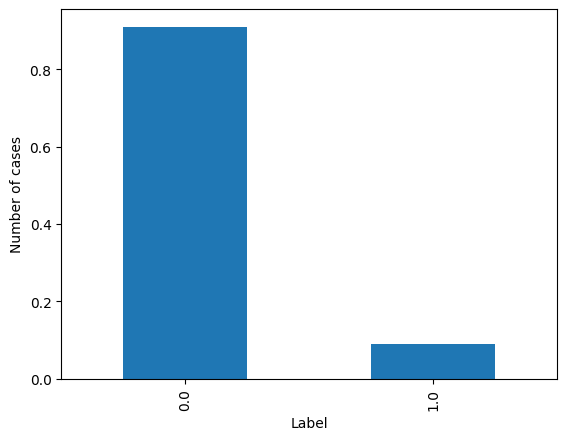

In [13]:
#Class Imabance Analysis
data.label.value_counts(normalize=True).plot(kind="bar");
plt.xlabel('Label');
plt.ylabel('Number of cases');

### Data Cleaning

##### Remove duplicates in the train data (not reproducible in Test as depends on the label)

In [14]:
data = data[data['label'].notna()].drop_duplicates()
data.shape

(190343, 16)

In [15]:
data.bin_type.value_counts(dropna=False)

bin_type
credit          80371
NaN             60408
debit           49536
credit/debit       28
Name: count, dtype: int64

In [16]:
#Apply the simplistic approach that we've came up with - Create a FeatureCleaner custom transformer
class DataCleaner(TransformerMixin):
    def __init__(self):
        pass
        
    def fit(self, X=None, y=None, **fit_params):
        return self
    
    def transform(self, X):
        _df = X.copy()

        # 0) Converdtypes
        _df['order_date']= pd.to_datetime(_df['order_date'], errors='coerce')
        _df['card_expiration_date']= pd.to_datetime(_df['card_expiration_date'], errors='coerce')
        
        # 1) Rename 'id'
        #_df = _df.rename(columns={'order_id':'id'})
        
        # 3) Impute previous orders column
        for col in ['email_amount_spent_avg_180d', 'email_orders_count_180d']:
            _df[col] = _df[col].fillna(0)

  
        #Future - Pottentially we want to explore shipping_method_type
        #Future - county codes may be worth exploring some high level grouping (continent, region, else)

    
        return _df




data_cleaner = DataCleaner()
data_cleaner_check = data_cleaner.fit_transform(data)
data_cleaner_check.head()

/tmp/ipykernel_13067/1405447400.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _df['card_expiration_date']= pd.to_datetime(_df['card_expiration_date'], errors='coerce')


,order_id,order_date,amount_usd,payment_method,billing_address_country_code,shipping_address_country_code,avs_code,email_amount_spent_avg_180d,email_orders_count_180d,session_visitor_type,shipping_method_type,card_expiration_date,bin_brand,bin_type,label,suspicious_activity_score
0,181852054,2022-06-02 15:28:13,611.03,payment_method_2,SA,SA,avs_code_8,0.000000,0.0,returning,E,2025-05-01,mastercard,credit,0.0,7.801596
1,181265052,2022-05-21 15:53:20,334.44,payment_method_1,FR,FR,avs_code_1,591.141667,6.0,returning,S,NaT,NaN,NaN,0.0,8.117476
2,149633145,2021-09-30 09:05:06,611.85,payment_method_1,HK,HK,avs_code_1,0.000000,0.0,returning,E;E,NaT,NaN,NaN,0.0,6.240885
3,149158895,2021-09-22 15:19:15,198.18,payment_method_2,RU,RU,avs_code_5,473.027368,38.0,returning,E,2023-03-01,visa,debit,0.0,5.188745
4,169664695,2022-02-18 08:59:32,434.71,payment_method_3,HK,HK,avs_code_5,0.000000,0.0,returning,E,NaT,NaN,NaN,0.0,5.738602


In [17]:
data_cleaner_check.dtypes

order_id                                  int64
order_date                       datetime64[ns]
amount_usd                              float64
payment_method                           object
billing_address_country_code             object
shipping_address_country_code            object
avs_code                                 object
email_amount_spent_avg_180d             float64
email_orders_count_180d                 float64
session_visitor_type                     object
shipping_method_type                     object
card_expiration_date             datetime64[ns]
bin_brand                                object
bin_type                                 object
label                                   float64
suspicious_activity_score               float64
dtype: object

In [18]:
data_cleaner_check.isnull().sum()

order_id                             0
order_date                           0
amount_usd                           0
payment_method                     610
billing_address_country_code        20
shipping_address_country_code       16
avs_code                          3377
email_amount_spent_avg_180d          0
email_orders_count_180d              0
session_visitor_type             34847
shipping_method_type                 0
card_expiration_date             58945
bin_brand                        60003
bin_type                         60408
label                                0
suspicious_activity_score            0
dtype: int64

### Feature Engineering

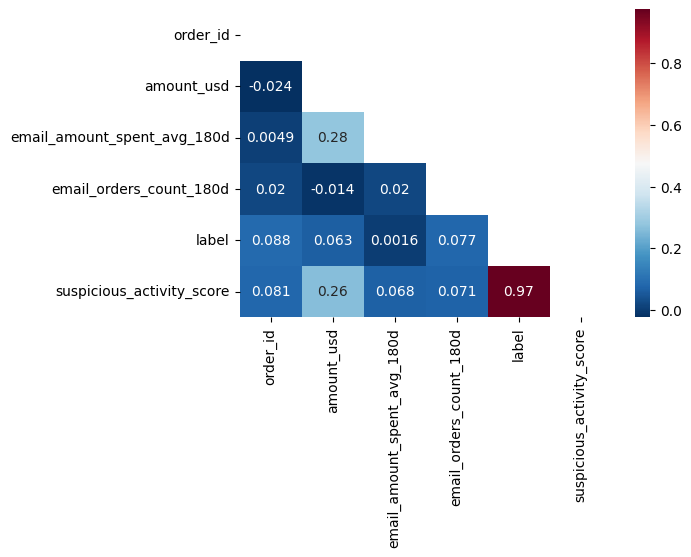

In [19]:
# Adding this after getting ROCAUC of 1.0
cor_mat = data.corr(numeric_only=True)
lower_triangle_mask = np.triu(np.ones(cor_mat.shape)).astype(bool)
cor_mat_lower = cor_mat.mask(lower_triangle_mask)

plt.figure(figsize = (6,4)) 

sns.heatmap(cor_mat_lower, 
            annot=True, 
            cmap='RdBu_r');

In [20]:
#Explore the data to identify new columns that we may find relevant to the problem

# Assess mutual information - is payment method worth keeping or should we drop?

In [23]:
#Create the new columns via custom transformer

class FeatureEngineering(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass
    
    def fit(self, X=None, y=None, **fit_params):
        return self
    
    def transform(self, X):
        _df = X.copy()
            
        _df['order_daypart'] = pd.cut(_df.order_date.dt.hour, [-1,5,11,17,23], labels=['dawn','morning','afternoon','evening'])
        _df['order_dow'] = _df.order_date.dt.dayofweek
        _df = _df.drop(columns=['order_date'])

        #Drop suspicious high correlation columns
        _df = _df.drop(columns = ['suspicious_activity_score'])
        
        #Remove columns that have no variance
        _df = _df.drop(columns = ['order_id'])

        
        #Remove non numerical columns with too many values so we go straight to one hot for all categoricals, study them better later
        _df = _df.drop(columns=['card_expiration_date', 'shipping_method_type', 'billing_address_country_code', 'shipping_address_country_code'])
        
        return _df 

In [24]:
feature_eng = FeatureEngineering()
treated_data = feature_eng.fit_transform(data_cleaner_check)
treated_data.head()

print(treated_data[['order_daypart']].head(5))
print(treated_data[['order_dow']].head(5))

  order_daypart
0     afternoon
1     afternoon
2       morning
3     afternoon
4       morning
   order_dow
0          3
1          5
2          3
3          2
4          4


In [25]:
treated_data.head()

,amount_usd,payment_method,avs_code,email_amount_spent_avg_180d,email_orders_count_180d,session_visitor_type,bin_brand,bin_type,label,order_daypart,order_dow
0,611.03,payment_method_2,avs_code_8,0.000000,0.0,returning,mastercard,credit,0.0,afternoon,3
1,334.44,payment_method_1,avs_code_1,591.141667,6.0,returning,NaN,NaN,0.0,afternoon,5
2,611.85,payment_method_1,avs_code_1,0.000000,0.0,returning,NaN,NaN,0.0,morning,3
3,198.18,payment_method_2,avs_code_5,473.027368,38.0,returning,visa,debit,0.0,afternoon,2
4,434.71,payment_method_3,avs_code_5,0.000000,0.0,returning,NaN,NaN,0.0,morning,4


In [26]:
#data.shipping_method_type.value_counts() 

### Model Training and Evaluation

#### Data Pipeline Prep

In [27]:
treated_data.select_dtypes(include=["object", "category"]).nunique()

payment_method           8
avs_code                24
session_visitor_type     2
bin_brand               10
bin_type                 3
order_daypart            4
dtype: int64

In [28]:
#Split the data - careful for imbalances, stratify needed, over/under sampling needed?
#Create data pipeline this and that for numerical, this and that for categorical, this and that..
numerical_pipeline = Pipeline(steps=[
    ("num_imputer", SimpleImputer(strategy='median')),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("cat_imputer", SimpleImputer(strategy="constant", fill_value = "Unknown")),
    ("onehot", OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

preprocess = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline, selector(dtype_include=np.number)),
        ("categorical", categorical_pipeline, selector(dtype_exclude=np.number)),
    ]
)

In [29]:
#Split data with stratify
X = data.drop(columns=[target_column])
y = data[target_column]

    
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size = 0.3, stratify = y, random_state = 42)

In [30]:
#Fit the model
pipeline = Pipeline(steps=[
    ('data_clean', DataCleaner()),
    ('feature_engineering',FeatureEngineering()),
    ('data_type_prep', preprocess),
    ('baseline_model', RandomForestClassifier(n_estimators=50,max_depth=None,min_samples_leaf=2,max_features="sqrt",class_weight="balanced_subsample", n_jobs = -1, random_state=42)),
])

pipeline.fit(X_train, y_train)

/tmp/ipykernel_13067/1405447400.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _df['card_expiration_date']= pd.to_datetime(_df['card_expiration_date'], errors='coerce')


,steps,"[('data_clean', ...), ('feature_engineering', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerical', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [31]:
#Calculate metrics of interest

probas_train = pipeline.predict_proba(X_train)[:, 1]
probas_valid = pipeline.predict_proba(X_valid)[:, 1]

roc_auc_train = roc_auc_score(y_train, probas_train)
roc_auc_valid = roc_auc_score(y_valid, probas_valid)

print(f"ROC AUC  Train: {roc_auc_train}")
print(f"ROC AUC  Valid: {roc_auc_valid}")


/tmp/ipykernel_13067/1405447400.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _df['card_expiration_date']= pd.to_datetime(_df['card_expiration_date'], errors='coerce')
/tmp/ipykernel_13067/1405447400.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _df['card_expiration_date']= pd.to_datetime(_df['card_expiration_date'], errors='coerce')


ROC AUC  Train: 0.9900569122880718
ROC AUC  Valid: 0.9186968158515214


In [ ]:
#Plot confusion matrix

/tmp/ipykernel_13067/1405447400.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _df['card_expiration_date']= pd.to_datetime(_df['card_expiration_date'], errors='coerce')


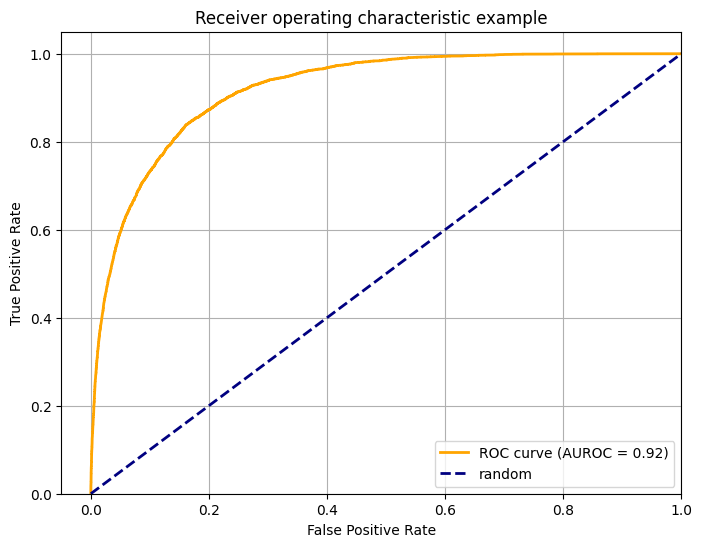

In [32]:
#Plot ROCAUC Curve
roc_auc = roc_auc_score(y_valid, probas_valid)
fpr, tpr, thresholds = roc_curve(y_score=pipeline.predict_proba(X_valid)[:,1], y_true=y_valid)
def plot_roc_curve(roc_auc, fpr, tpr):
    
    plt.figure(figsize=(8,6))
    lw = 2
    plt.plot(fpr, tpr, color='orange', lw=lw, label='ROC curve (AUROC = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=lw, linestyle='--', label='random')
    plt.xlim([-0.05, 1.0])
    plt.ylim([0.0, 1.05])
    plt.grid()
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver operating characteristic example')
    plt.legend(loc="lower right")
    plt.show()
plot_roc_curve(roc_auc, fpr, tpr)

In [ ]:
#Optional - do we need to check for ROC AUC across different segments of our data to guarantee fairness?

### Submission

In [39]:
#Load Test Data and do basic check
X_test = pd.read_csv("data/test.csv")
X_test['id']=X_test['order_id']
X_test = X_test.set_index('id')
X_test.head()

,order_id,order_date,amount_usd,payment_method,billing_address_country_code,shipping_address_country_code,avs_code,email_amount_spent_avg_180d,email_orders_count_180d,session_visitor_type,shipping_method_type,card_expiration_date,bin_brand,bin_type,suspicious_activity_score
id,,,,,,,,,,,,,,,
191025041,191025041,2022-08-02 18:32:51,121.90,payment_method_1,GB,GB,avs_code_1,NaN,NaN,returning,S,NaN,NaN,NaN,0
191796174,191796174,2022-08-16 14:00:44,98.74,payment_method_1,GB,GB,avs_code_1,NaN,NaN,new,S,NaN,NaN,NaN,0
202905772,202905772,2022-11-22 02:49:31,117.03,payment_method_2,MX,MX,avs_code_3,NaN,NaN,returning,E,09/2026,mastercard,credit,0
204355210,204355210,2022-11-25 09:49:33,629.51,payment_method_1,GB,GB,avs_code_1,NaN,NaN,returning,S,NaN,NaN,NaN,0
190036435,190036435,2022-08-01 14:21:45,427.32,payment_method_2,BE,BE,avs_code_3,NaN,NaN,returning,S,05/2027,visa,debit,0


In [40]:
#Use pipeline to predict probas
y_scores_final = pipeline.predict_proba(X_test)[:, 1]

/tmp/ipykernel_13067/1405447400.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _df['card_expiration_date']= pd.to_datetime(_df['card_expiration_date'], errors='coerce')


In [42]:
#Prepare submission file - IMPORTANT: submission id name needs to be renamed
submission = pd.Series(y_scores_final,index=X_test.index, name='result')
submission.to_csv("data/submission_0.csv")